# NFL Win Prediction: MLP

A neural network (multilayer perceptron) that predicts whether a team wins a game. The inputs are the team's stats averaged over its last 3 games, whether it's at home, and its win rate so far this season. The second version also gets the opponent's stats and both teams' records from last season. The settings are tuned on the validation seasons and the final model is checked once on the test seasons. It uses the same splits as the Bayesian model so the results can be compared.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import keras
from keras.models import Model
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss

# Folder written by the data processing notebook
DATA_DIR = Path("../Data/data/processed")

In [2]:
# the test seasons (2022-2026) only get used once at the end, after the model is picked
series = pd.read_csv(DATA_DIR / "nfl_team_game_model_data.csv")
train = pd.read_csv(DATA_DIR / "nfl_train.csv")
validation = pd.read_csv(DATA_DIR / "nfl_validation.csv")
test = pd.read_csv(DATA_DIR / "nfl_test.csv")

# the input features are listed in feature_descriptions.csv from the data processing notebook
features = pd.read_csv(DATA_DIR / "feature_descriptions.csv")["feature"].tolist()

print("Rows (train / validation / test):", len(train), len(validation), len(test))
print(len(features), "features:", features)

Rows (train / validation / test): 9518 2064 2485
19 features: ['passing_yards_avg_last_3', 'passing_tds_avg_last_3', 'passing_interceptions_avg_last_3', 'passing_epa_avg_last_3', 'rushing_yards_avg_last_3', 'rushing_tds_avg_last_3', 'rushing_epa_avg_last_3', 'receiving_yards_avg_last_3', 'def_sacks_avg_last_3', 'def_interceptions_avg_last_3', 'def_tds_avg_last_3', 'pt_net_yards_avg_last_3', 'fumbles_lost_total_avg_last_3', 'total_offensive_yards_avg_last_3', 'total_team_tds_avg_last_3', 'turnover_margin_avg_last_3', 'fg_pct_last_3', 'is_home', 'prior_win_rate']


In [3]:
# last season's win rate. teams with no last season in the data (everyone in 1999) get 0.5
for df in [series, train, validation, test]:
    df["prev_win_rate"] = (
        df["prev_season_wins"] / df["prev_season_games"].replace(0, np.nan)
    ).fillna(0.5)

# every game has a row for each team, so look up the opponent's row from the same game.
# their stats are also averages from before the game, so nothing from the game itself leaks in
team_features = [f for f in features if f != "is_home"] + ["prev_win_rate"]
opp_stats = series[["game_id", "team"] + team_features].copy()
opp_stats.columns = ["game_id", "opponent_team"] + ["opp_" + f for f in team_features]

train = train.merge(opp_stats, on=["game_id", "opponent_team"], how="left", validate="one_to_one")
validation = validation.merge(opp_stats, on=["game_id", "opponent_team"], how="left",
                              validate="one_to_one")
test = test.merge(opp_stats, on=["game_id", "opponent_team"], how="left", validate="one_to_one")

print("rows missing the opponent (train / validation / test):",
      train["opp_prior_win_rate"].isna().sum(), validation["opp_prior_win_rate"].isna().sum(),
      test["opp_prior_win_rate"].isna().sum())

rows missing the opponent (train / validation / test): 56 6 3


In [4]:
# version 1 is the team's own stats only. version 2 adds last season's record, how many games
# the team has played this season (how much to trust prior_win_rate), and the opponent's stats
own_features = features
full_features = features + ["prev_win_rate", "season_games_before"] + ["opp_" + f for f in team_features]
print("own stats:", len(own_features), "inputs")
print("with opponent:", len(full_features), "inputs")

y_train = train["win"].to_numpy()
y_val = validation["win"].to_numpy()
y_test = test["win"].to_numpy()

own stats: 19 inputs
with opponent: 40 inputs


In [5]:
def scale(cols):
    # the features are on really different scales (passing yards is in the hundreds and fg %
    # is between 0 and 1), so standardize them. the mean and sd come from the training set only
    scaler = StandardScaler().fit(train[cols])
    X_train = scaler.transform(train[cols])
    X_val = scaler.transform(validation[cols])
    X_test = scaler.transform(test[cols])

    # the few rows missing the opponent are NaN. after scaling the training mean is 0,
    # so filling with 0 treats the opponent as an average team
    return (np.nan_to_num(X_train, nan=0.0), np.nan_to_num(X_val, nan=0.0),
            np.nan_to_num(X_test, nan=0.0))


def make_model(n_inputs, hidden=(32, 16), dropout=0.2, lr=0.001):
    # hidden layers with relu and a sigmoid output, so the model gives P(win)
    keras.utils.set_random_seed(42)  # so results are the same each run

    inpx = Input(shape=(n_inputs,))
    x = inpx
    for n in hidden:
        x = Dense(n, activation="relu")(x)
        x = Dropout(dropout)(x)
    output = Dense(1, activation="sigmoid")(x)

    model = Model(inpx, output)
    model.compile(optimizer=Adam(learning_rate=lr), loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

In [6]:
# same model and settings for both versions, so the only difference is the inputs
histories = {}
rows = []
for name, cols in [("own stats", own_features), ("with opponent", full_features)]:
    X_train, X_val, _ = scale(cols)
    model = make_model(len(cols))
    histories[name] = model.fit(X_train, y_train, epochs=30, batch_size=32,
                                validation_data=(X_val, y_val), verbose=0)

    p_val = model.predict(X_val, verbose=0).ravel()
    val_loss = histories[name].history["val_loss"]
    rows.append({"inputs": name, "n_inputs": len(cols),
                 "val_accuracy": accuracy_score(y_val, p_val > 0.5),
                 "val_log_loss": log_loss(y_val, p_val),
                 "best_epoch": int(np.argmin(val_loss)) + 1,
                 "lowest_val_log_loss": min(val_loss)})

model.summary()  # the "with opponent" model
results = pd.DataFrame(rows).round(4)
results

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,573 (21.77 KB)

 Trainable params: 1,857 (7.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,716 (14.52 KB)

,inputs,n_inputs,val_accuracy,val_log_loss,best_epoch,lowest_val_log_loss
0,own stats,19,0.5761,0.6788,3,0.6743
1,with opponent,40,0.6134,0.6576,4,0.6441


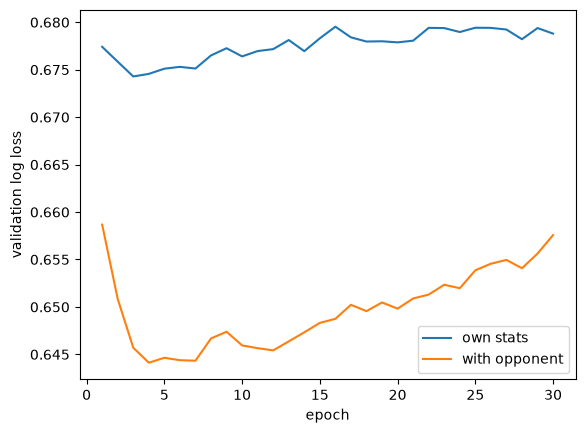

always pick the home team: 0.534


In [7]:
# keras counts epochs from 0, so start the axis at 1 to match best_epoch in the table above
for name, h in histories.items():
    epochs = range(1, len(h.history["val_loss"]) + 1)
    plt.plot(epochs, h.history["val_loss"], label=name)
plt.xlabel("epoch")
plt.ylabel("validation log loss")
plt.legend()
plt.show()

# baseline: always pick the home team
print("always pick the home team:", round(accuracy_score(y_val, validation["is_home"]), 3))

Adding the opponent and last season's record helps a lot. Validation accuracy goes from about 58% to 61% and the log loss drops from 0.679 to 0.658. That makes sense since who a team is playing matters a lot.

Both versions still overfit. The validation loss for the opponent version is lowest at epoch 4 (0.644) and then goes up for the rest of training. At that point it's close to the Bayesian model, which gets 0.641 on the same seasons. The next step is to tune the number of epochs, the layer sizes, dropout and the learning rate on the validation set.

In [8]:
# tune on the validation seasons. each setting trains for 40 epochs and we keep the epoch
# where the validation loss was lowest, since the model starts overfitting after that
X_train, X_val, X_test = scale(full_features)

rows = []
for hidden in [(16,), (32, 16)]:
    for dropout in [0.2, 0.4]:
        for lr in [0.001, 0.0003]:
            model = make_model(len(full_features), hidden=hidden, dropout=dropout, lr=lr)
            h = model.fit(X_train, y_train, epochs=40, batch_size=32,
                          validation_data=(X_val, y_val), verbose=0)
            best = int(np.argmin(h.history["val_loss"]))
            rows.append({"hidden": hidden, "dropout": dropout, "lr": lr,
                         "best_epoch": best + 1,
                         "val_log_loss": h.history["val_loss"][best],
                         "val_accuracy": h.history["val_accuracy"][best]})

tuning = pd.DataFrame(rows).sort_values("val_log_loss").reset_index(drop=True)
tuning.round(4)

,hidden,dropout,lr,best_epoch,val_log_loss,val_accuracy
0,"(16,)",0.4,0.0010,6,0.6383,0.6255
1,"(16,)",0.2,0.0010,4,0.6391,0.6235
2,"(16,)",0.4,0.0003,26,0.6395,0.6308
3,"(16,)",0.2,0.0003,14,0.6401,0.6265
4,"(32, 16)",0.2,0.0003,22,0.6439,0.6182
5,"(32, 16)",0.2,0.0010,4,0.6441,0.6172
6,"(32, 16)",0.4,0.0003,38,0.6445,0.6197
7,"(32, 16)",0.4,0.0010,17,0.6447,0.6240


In [9]:
# retrain the best setting for its best number of epochs
best = tuning.iloc[0]
print("picked:", best["hidden"], "hidden, dropout", best["dropout"], "lr", best["lr"],
      "for", best["best_epoch"], "epochs")

final_model = make_model(len(full_features), hidden=best["hidden"], dropout=best["dropout"],
                         lr=best["lr"])
final_model.fit(X_train, y_train, epochs=int(best["best_epoch"]), batch_size=32, verbose=0)

p_val = final_model.predict(X_val, verbose=0).ravel()
print("validation accuracy:", round(accuracy_score(y_val, p_val > 0.5), 3))
print("validation log loss:", round(log_loss(y_val, p_val), 4))

picked: (16,) hidden, dropout 0.4 lr 0.001 for 6 epochs


validation accuracy: 0.625
validation log loss: 0.6383


All four settings with one hidden layer of 16 nodes do better than the four with two layers (32 and 16). The bigger model overfits faster, which makes sense with only about 9,500 training rows. The picked setting is 16 nodes, dropout 0.4 and a learning rate of 0.001 for 6 epochs. That gets a validation log loss of 0.638 and about 63% accuracy. This is about the same as the Bayesian model on the same seasons (0.641).

In [10]:
# test seasons, only run once with the picked model
p_test = final_model.predict(X_test, verbose=0).ravel()
test["prob"] = p_test
test["pred"] = (p_test > 0.5).astype(int)

# compare against the Bayesian model's predictions on the same test games
bayes = pd.read_csv(DATA_DIR / "predictions_bayes.csv")
both = test.merge(bayes[["game_id", "team", "prob"]], on=["game_id", "team"],
                  suffixes=("", "_bayes"), validate="one_to_one")

comparison = pd.DataFrame([
    {"model": "MLP", "accuracy": accuracy_score(both["win"], both["prob"] > 0.5),
     "log_loss": log_loss(both["win"], both["prob"])},
    {"model": "Bayesian (head-to-head + home)",
     "accuracy": accuracy_score(both["win"], both["prob_bayes"] > 0.5),
     "log_loss": log_loss(both["win"], both["prob_bayes"])},
    {"model": "Always pick the home team",
     "accuracy": accuracy_score(both["win"], both["is_home"]), "log_loss": np.nan},
])
print("test rows:", len(both))
print("same pick as the Bayesian model:",
      round(((both["prob"] > 0.5) == (both["prob_bayes"] > 0.5)).mean(), 3))
comparison.round(4)

test rows: 2485
same pick as the Bayesian model: 0.833


,model,accuracy,log_loss
0,MLP,0.6149,0.6481
1,Bayesian (head-to-head + home),0.6274,0.6464
2,Always pick the home team,0.5416,NaN


In [11]:
# save predictions in the same format as the Bayesian notebook
out = test[["game_id", "team", "season", "week", "win", "prob", "pred"]]
out.to_csv(DATA_DIR / "predictions_mlp.csv", index=False)
print("Saved:", DATA_DIR / "predictions_mlp.csv", out.shape)

Saved: ../Data/data/processed/predictions_mlp.csv (2485, 7)


On the test seasons the MLP gets 61.5% accuracy and a log loss of 0.648. Always picking the home team only gets 54.2%, so the model is clearly learning something. The Bayesian model is a little better on both (62.7% and 0.646). The difference is small though. The two models pick the same winner in about 83% of the test games.

It's a little surprising that the MLP doesn't beat a model that only uses win-loss records. One reason might be that 3-game averages are noisy. One bad game can change a team's averages a lot, while the win rate changes slowly.